In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from collections import Counter


In [2]:
path = "games.csv"

cols = pd.read_csv(path, nrows=0).columns.tolist()
i = cols.index("DiscountDLC count")
cols[i:i+1] = ["Discount", "DLC count"]
df = pd.read_csv(path, header=None, skiprows=1, names=cols)

# Part 1

In [3]:
print(f"Shape: {df.shape}")

Shape: (125855, 40)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 125855 entries, 0 to 125854
Data columns (total 40 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   AppID                       125855 non-null  int64  
 1   Name                        125854 non-null  str    
 2   Release date                125855 non-null  str    
 3   Estimated owners            125855 non-null  str    
 4   Peak CCU                    125855 non-null  int64  
 5   Required age                125855 non-null  int64  
 6   Price                       125855 non-null  float64
 7   Discount                    125855 non-null  int64  
 8   DLC count                   125855 non-null  int64  
 9   About the game              117393 non-null  str    
 10  Supported languages         125855 non-null  str    
 11  Full audio languages        125855 non-null  str    
 12  Reviews                     12181 non-null   str    
 13  Header image             

In [5]:
df.describe()

,AppID,Peak CCU,Required age,Price,Discount,DLC count,Metacritic score,User score,Positive,Negative,Score rank,Achievements,Recommendations,Average playtime forever,Average playtime two weeks,Median playtime forever,Median playtime two weeks,Movies
count,1.258550e+05,1.258550e+05,125855.000000,125855.000000,125855.000000,125855.000000,125855.000000,125855.000000,1.258550e+05,1.258550e+05,40.000000,125855.000000,1.258550e+05,1.258550e+05,125855.000000,1.258550e+05,125855.000000,0.0
mean,2.032627e+06,5.318720e+01,0.165365,4.811174,17.896826,0.535434,2.500083,0.023916,1.018182e+03,1.648786e+02,99.175000,17.922220,9.380399e+02,2.027568e+02,13.507711,1.691803e+02,14.419125,NaN
std,1.117434e+06,3.681083e+03,1.642666,12.489329,28.628518,14.328417,13.492922,1.376811,2.772782e+04,5.305001e+03,0.675107,139.696425,2.159585e+04,1.107222e+04,266.925759,1.105725e+04,290.747134,NaN
min,1.000000e+01,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,98.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000,NaN
25%,1.083495e+06,0.000000e+00,0.000000,0.590000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,99.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000,NaN
50%,1.949010e+06,0.000000e+00,0.000000,2.390000,0.000000,0.000000,0.000000,0.000000,4.000000e+00,1.000000e+00,99.000000,2.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000,NaN
75%,2.938410e+06,0.000000e+00,0.000000,5.545000,37.000000,0.000000,0.000000,0.000000,3.500000e+01,1.000000e+01,100.000000,19.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000,NaN
max,4.437540e+06,1.013936e+06,21.000000,999.980000,100.000000,3703.000000,97.000000,100.000000,7.642084e+06,1.173003e+06,100.000000,9821.000000,4.830455e+06,3.429544e+06,20088.000000,3.429544e+06,20088.000000,NaN


In [6]:
df['Release date'] = pd.to_datetime(df['Release date'])

In [7]:
df['total_reviews'] = df['Positive'] + df['Negative']

In [8]:

df = df[df['Estimated owners'] != '0 - 0']
df = df[df['total_reviews'] >= 10]
df = df[df['Release date'] < pd.to_datetime('2026-11-01')]

In [9]:
columns_to_drop = ['Movies','Developers','Publishers',
       'Metacritic url','Header image','Website',
       'Support url', 'Support email','About the game', 
       'Score rank', 'Notes', 'User score','Average playtime two weeks', 'Median playtime two weeks']

#developers, publishers, metacritic url, header images, website, support url, 
# support email, about the game don't provide data that's useful for analysis
# the rest are empty or near empty

df.drop(columns=columns_to_drop,inplace=True)

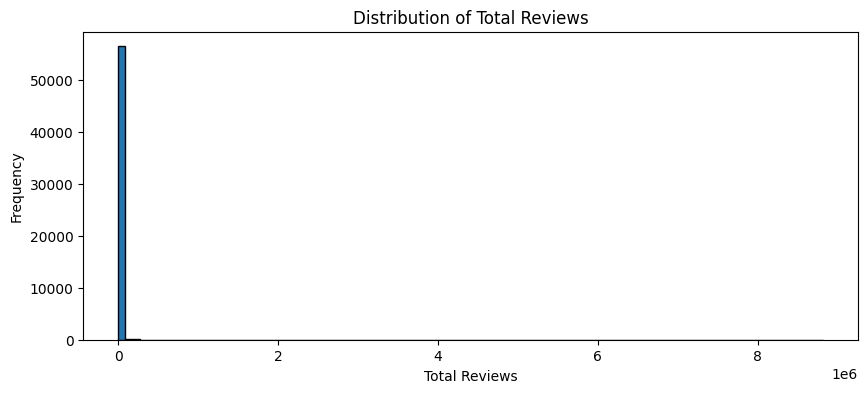

In [10]:
plt.figure(figsize=(10,4))
plt.hist(df['total_reviews'], bins=100, edgecolor='black')
plt.title('Distribution of Total Reviews')
plt.xlabel('Total Reviews')
plt.ylabel('Frequency')
plt.show()

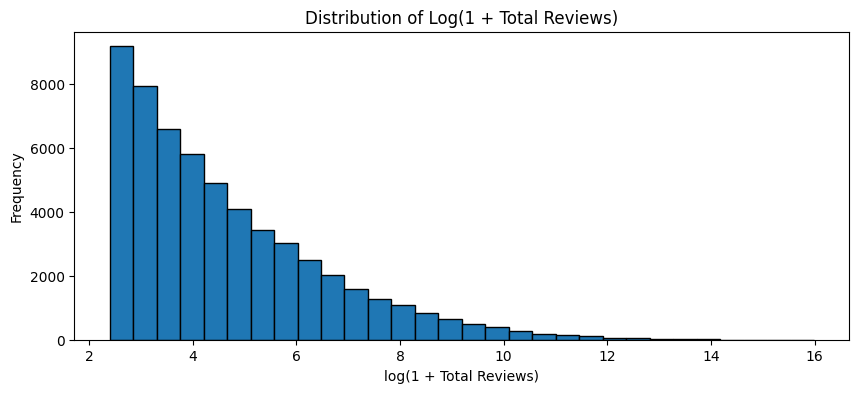

In [11]:
plt.figure(figsize=(10,4))
plt.hist(np.log1p(df['total_reviews']), bins=30, edgecolor='black')
plt.title('Distribution of Log(1 + Total Reviews)')
plt.xlabel('log(1 + Total Reviews)')
plt.ylabel('Frequency')
plt.show()

#log version makes it much easier to see the distribution compared to raw histogram

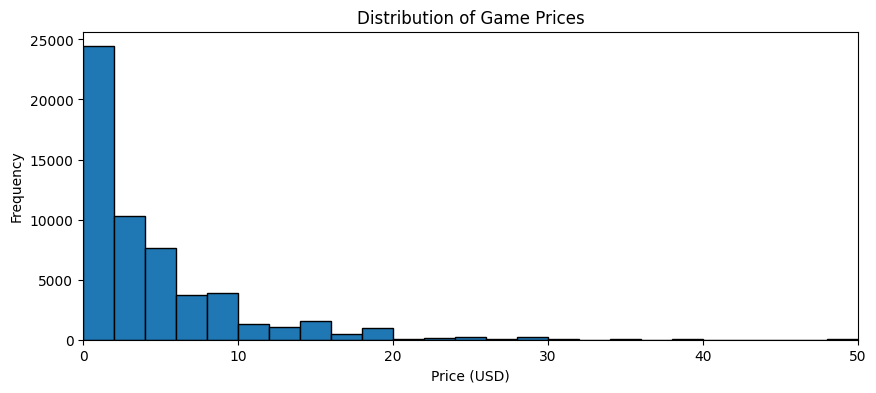

In [12]:
plt.figure(figsize=(10,4))
plt.xlim(0,50)
plt.hist(df['Price'], bins=150, edgecolor='black')
plt.title('Distribution of Game Prices')
plt.xlabel('Price (USD)')
plt.ylabel('Frequency')
plt.show()

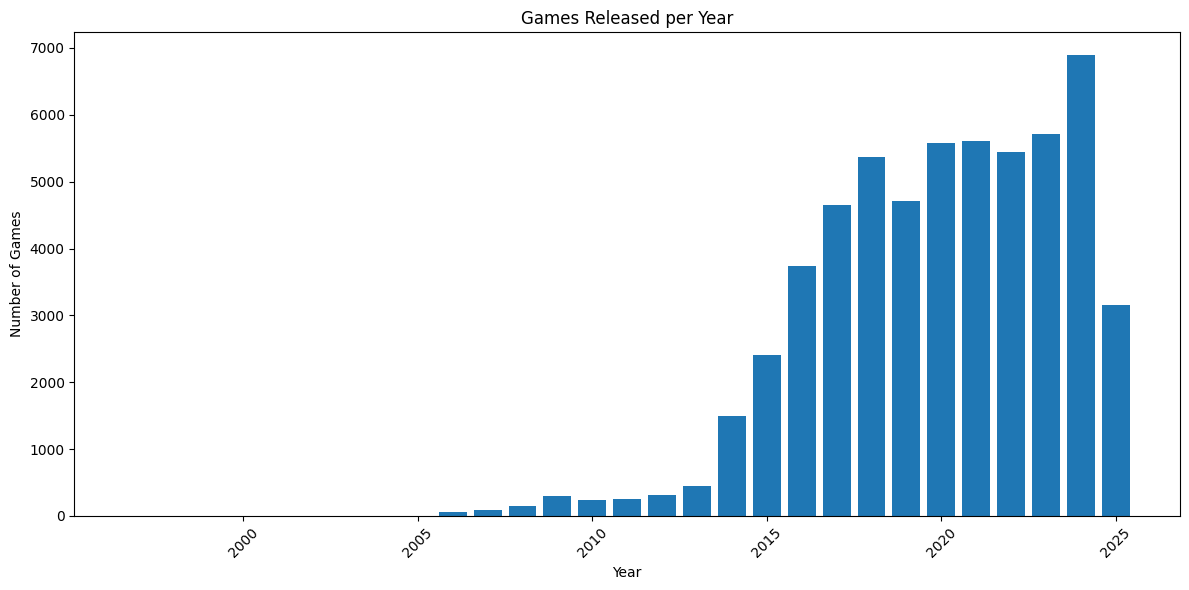

In [13]:

year_counter = Counter(df['Release date'].dt.year)
years = list(year_counter)
amount_per_year = list(year_counter.values())

plt.figure(figsize=(12, 6))
plt.bar(years, amount_per_year)
plt.title('Games Released per Year')
plt.xlabel('Year')
plt.ylabel('Number of Games')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
def remove_outliers(data, column, ratio):
    log_data = np.log1p(data[column])
    
    Q1 = log_data.quantile(0.25)
    Q3 = log_data.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - (ratio * IQR)
    upper_bound = Q3 + (ratio * IQR)
    
    filtered_data = data[(log_data >= lower_bound) & (log_data <= upper_bound)]
    filtered_data = filtered_data.dropna(subset=[column])
    print(f'Length before removal of {column} outliers: {len(data)}')
    print(f'Length after: {len(filtered_data)}')
    return filtered_data

In [15]:

clean_data = remove_outliers(df,'Price',1.5)
clean_data = remove_outliers(clean_data,'Achievements',1.5)
clean_data = remove_outliers(clean_data,'Average playtime forever',1.5)
clean_data = remove_outliers(clean_data,'Median playtime forever',1.5)
clean_data = remove_outliers(clean_data,'total_reviews',1.5)

Length before removal of Price outliers: 56662
Length after: 56454
Length before removal of Achievements outliers: 56454
Length after: 56375
Length before removal of Average playtime forever outliers: 56375
Length after: 56373
Length before removal of Median playtime forever outliers: 56373
Length after: 56372
Length before removal of total_reviews outliers: 56372
Length after: 54912


# Part 2

In [16]:
clean_data['release_year'] = clean_data['Release date'].dt.year

#using 2025 to get the age of the game at the time the data was collected rather than age today
clean_data['game_age_years'] = 2025 - clean_data['Release date'].dt.year 

In [17]:
def find_midpoint(owners_range:str):
    r = owners_range.split('-')
    bottom = int(r[0].strip())
    top = int(r[1].strip())
    
    return (bottom+top)/2
    
clean_data['owners_mid'] = [find_midpoint(x) for x in clean_data['Estimated owners']]

In [18]:
clean_data['original_price'] = clean_data['Price'] / (1 - (clean_data['Discount'].where(clean_data['Discount'] < 100, 0)/100))
clean_data['original_price'].describe()

count    54912.000000
mean         7.849522
std          9.449209
min          0.000000
25%          1.877742
50%          4.988235
75%          9.990000
max        266.600000
Name: original_price, dtype: float64

In [19]:
clean_data['is_free'] = [x==0 for x in clean_data['Price']]
clean_data['n_languages'] = [x.count(',')+1 for x in clean_data['Supported languages']]
clean_data['n_tags'] = [len(str(x).split(',')) for x in clean_data['Tags']]
clean_data['n_screenshots'] = [len(str(x).split(',')) for x in clean_data['Screenshots']]
clean_data['n_platforms'] = np.array([int(x) for x in clean_data['Windows']])  + np.array([int(x) for x in clean_data['Mac']]) + np.array([int(x) for x in clean_data['Linux']])
clean_data['has_metacritic'] = [x>0 for x in clean_data['Metacritic score']]

clean_data.head()


,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,Discount,DLC count,Supported languages,...,release_year,game_age_years,owners_mid,original_price,is_free,n_languages,n_tags,n_screenshots,n_platforms,has_metacritic
1,496350,Supipara - Chapter 1 Spring Has Come!,2016-07-29,0 - 20000,0,0,5.24,65,0,['English'],...,2016,9,10000.0,14.971429,False,1,4,10,1,False
2,1034400,Mystery Solitaire The Black Raven,2019-05-06,0 - 20000,0,0,4.99,0,0,"['English', 'French', 'German', 'Russian']",...,2019,6,10000.0,4.990000,False,4,16,7,2,False
6,1934300,Armored Brigade II,2025-04-08,0 - 20000,8,0,35.99,10,1,['English'],...,2025,0,10000.0,39.988889,False,1,18,12,1,False
8,1157670,Hepta Beats,2021-05-07,0 - 20000,0,0,0.99,0,0,"['English', 'French', 'Italian', 'German', 'Sp...",...,2021,4,10000.0,0.990000,False,29,12,7,1,False
9,1540330,MUMBA IV: Egypt Jewels,2021-12-13,0 - 20000,1,0,0.59,0,1,"['English', 'French', 'Italian', 'German', 'Sp...",...,2021,4,10000.0,0.590000,False,30,7,13,3,False


In [20]:
genres = []
for x in clean_data['Genres']:
    genres.extend(str(x).split(','))



genres_count = Counter(genres).most_common()

genres_to_keep = []
for i in range(10):
    genres_to_keep.append(genres_count[i][0])

for genre in genres_to_keep:
    clean_data[genre] = [genre in str(x) for x in clean_data['Genres']]
    
clean_data.head()

,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,Discount,DLC count,Supported languages,...,Indie,Adventure,Action,Casual,Simulation,Strategy,RPG,Early Access,Free To Play,Sports
1,496350,Supipara - Chapter 1 Spring Has Come!,2016-07-29,0 - 20000,0,0,5.24,65,0,['English'],...,False,True,False,False,False,False,False,False,False,False
2,1034400,Mystery Solitaire The Black Raven,2019-05-06,0 - 20000,0,0,4.99,0,0,"['English', 'French', 'German', 'Russian']",...,False,False,False,True,False,False,False,False,False,False
6,1934300,Armored Brigade II,2025-04-08,0 - 20000,8,0,35.99,10,1,['English'],...,False,False,False,False,True,True,False,False,False,False
8,1157670,Hepta Beats,2021-05-07,0 - 20000,0,0,0.99,0,0,"['English', 'French', 'Italian', 'German', 'Sp...",...,True,False,False,True,False,False,False,False,False,False
9,1540330,MUMBA IV: Egypt Jewels,2021-12-13,0 - 20000,1,0,0.59,0,1,"['English', 'French', 'Italian', 'German', 'Sp...",...,True,False,True,True,False,True,False,False,False,False


In [21]:
categories = []
for x in clean_data['Categories']:
    categories.extend(str(x).split(','))



cat_count = Counter(categories).most_common()

cats_to_keep = []
for i in range(10):
    cats_to_keep.append(cat_count[i][0])

for category in cats_to_keep:
    clean_data[category] = [category in str(x) for x in clean_data['Categories']]
    
clean_data.head()

,AppID,Name,Release date,Estimated owners,Peak CCU,Required age,Price,Discount,DLC count,Supported languages,...,Single-player,Family Sharing,Steam Achievements,Steam Cloud,Full controller support,Multi-player,Steam Trading Cards,Partial Controller Support,PvP,Co-op
1,496350,Supipara - Chapter 1 Spring Has Come!,2016-07-29,0 - 20000,0,0,5.24,65,0,['English'],...,True,True,False,True,False,False,True,False,False,False
2,1034400,Mystery Solitaire The Black Raven,2019-05-06,0 - 20000,0,0,4.99,0,0,"['English', 'French', 'German', 'Russian']",...,True,True,False,False,False,False,False,False,False,False
6,1934300,Armored Brigade II,2025-04-08,0 - 20000,8,0,35.99,10,1,['English'],...,True,True,False,True,False,False,False,False,False,False
8,1157670,Hepta Beats,2021-05-07,0 - 20000,0,0,0.99,0,0,"['English', 'French', 'Italian', 'German', 'Sp...",...,True,True,True,False,True,False,False,False,False,False
9,1540330,MUMBA IV: Egypt Jewels,2021-12-13,0 - 20000,1,0,0.59,0,1,"['English', 'French', 'Italian', 'German', 'Sp...",...,True,True,True,True,True,False,False,False,False,False


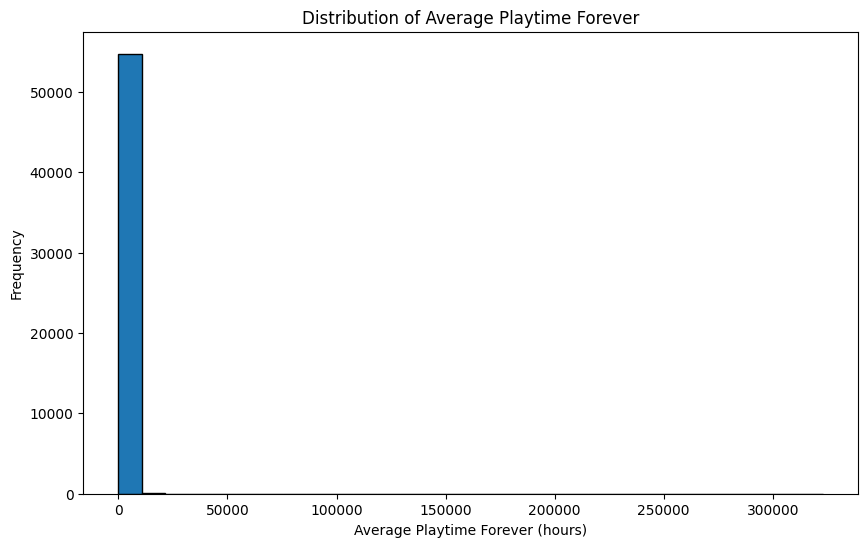

In [22]:
#before histogram
plt.figure(figsize=(10, 6))
plt.hist(clean_data['Average playtime forever'], bins=30, edgecolor='black')
plt.title('Distribution of Average Playtime Forever')
plt.xlabel('Average Playtime Forever (hours)')
plt.ylabel('Frequency')
plt.show()

In [23]:
clean_data['DLC count'] = np.log1p(clean_data['DLC count'])
clean_data['owners_mid'] = np.log1p(clean_data['owners_mid'])
clean_data['Achievements'] = np.log1p(clean_data['Achievements'])
clean_data['Peak CCU'] = np.log1p(clean_data['Peak CCU'])
clean_data['Average playtime forever'] = np.log1p(clean_data['Average playtime forever'])
clean_data['Median playtime forever'] = np.log1p(clean_data['Median playtime forever'])

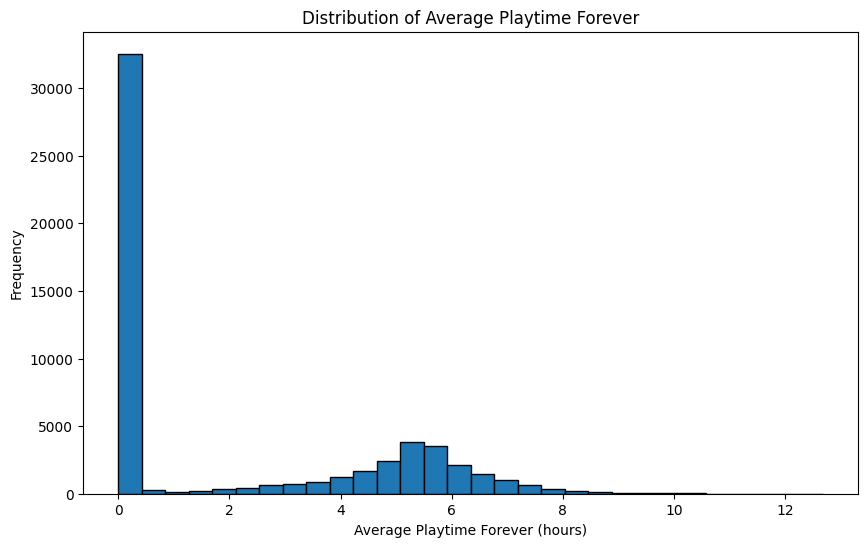

In [24]:
## after histogram
plt.figure(figsize=(10, 6))
plt.hist(clean_data['Average playtime forever'], bins=30, edgecolor='black')
plt.title('Distribution of Average Playtime Forever')
plt.xlabel('Average Playtime Forever (hours)')
plt.ylabel('Frequency')
plt.show()


In [25]:
# data leakage: Positive, Negative, Recommendations, User score, and Score rank
# are data points that are derived from the game's reviews, 
# so they should not be used for review prediction

In [26]:
clean_data.columns

Index(['AppID', 'Name', 'Release date', 'Estimated owners', 'Peak CCU',
       'Required age', 'Price', 'Discount', 'DLC count', 'Supported languages',
       'Full audio languages', 'Reviews', 'Windows', 'Mac', 'Linux',
       'Metacritic score', 'Positive', 'Negative', 'Achievements',
       'Recommendations', 'Average playtime forever',
       'Median playtime forever', 'Categories', 'Genres', 'Tags',
       'Screenshots', 'total_reviews', 'release_year', 'game_age_years',
       'owners_mid', 'original_price', 'is_free', 'n_languages', 'n_tags',
       'n_screenshots', 'n_platforms', 'has_metacritic', 'Indie', 'Adventure',
       'Action', 'Casual', 'Simulation', 'Strategy', 'RPG', 'Early Access',
       'Free To Play', 'Sports', 'Single-player', 'Family Sharing',
       'Steam Achievements', 'Steam Cloud', 'Full controller support',
       'Multi-player', 'Steam Trading Cards', 'Partial Controller Support',
       'PvP', 'Co-op'],
      dtype='str')

In [27]:
pre_launch = ['original_price','Required age', 'is_free', 'n_languages', 'n_tags',
       'n_screenshots', 'n_platforms','Achievements', 'Indie', 'Adventure',
       'Action', 'Casual', 'Simulation', 'Strategy', 'RPG', 'Early Access',
       'Free To Play', 'Sports','Single-player',
       'Family Sharing', 'Steam Achievements', 'Steam Cloud',
       'Full controller support', 'Multi-player', 
       'Partial Controller Support', 'PvP', 'Co-op']

post_launch = ['owners_mid','has_metacritic','Average playtime forever','Median playtime forever','Peak CCU','DLC count','game_age_years','Steam Trading Cards']


In [28]:
clean_data['log_reviews'] = np.log1p(clean_data['total_reviews'])

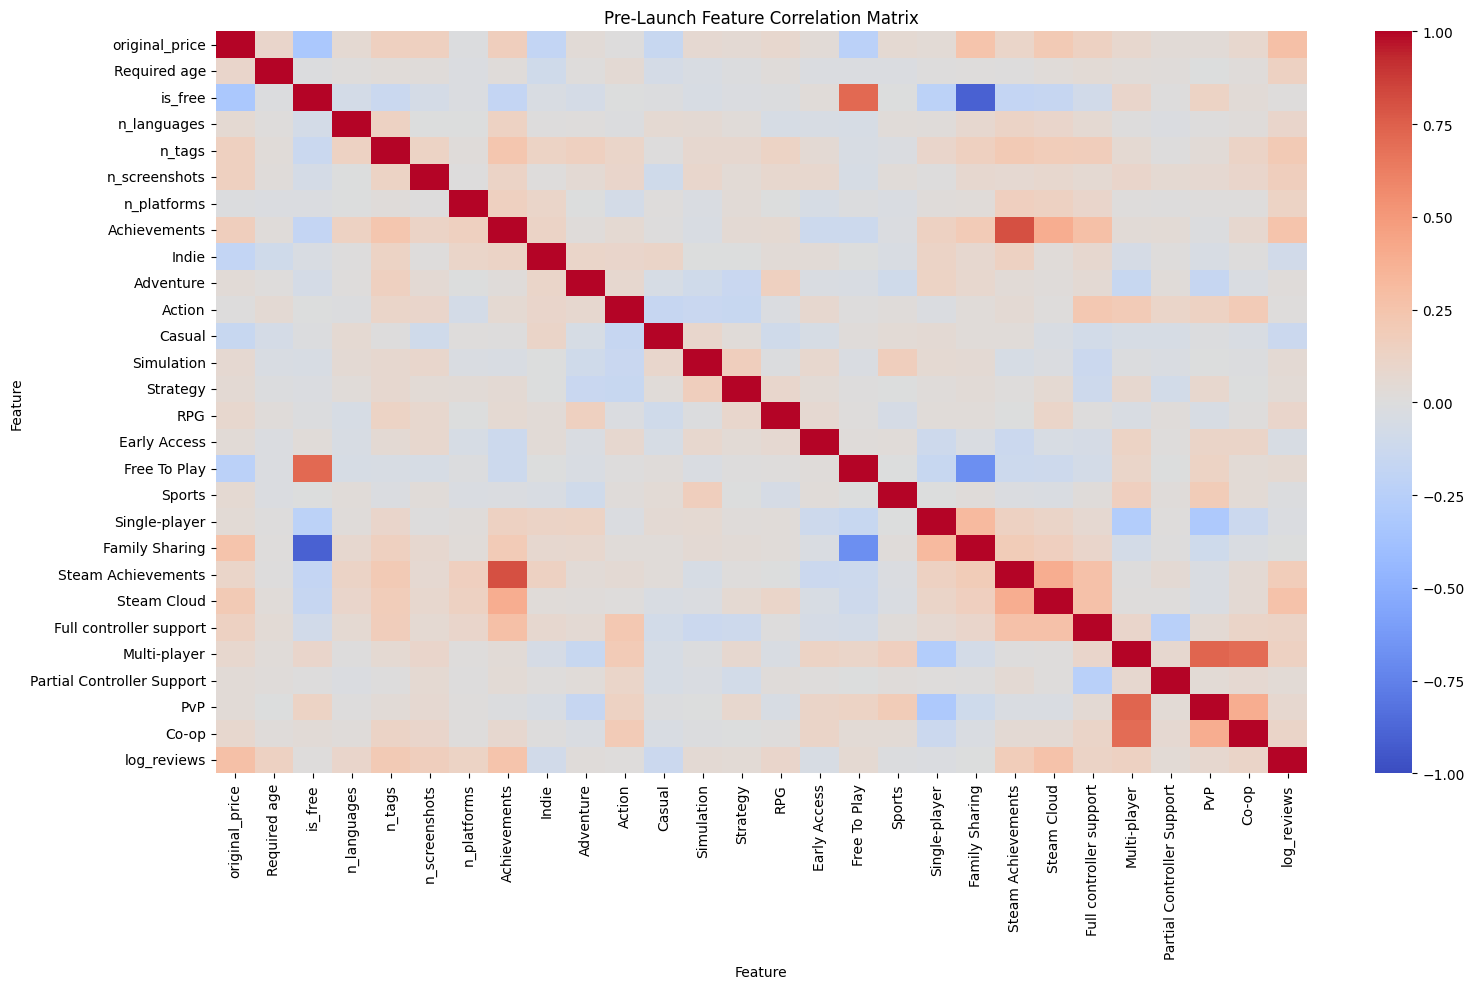

In [29]:
pre_launch_corr = clean_data[pre_launch+['log_reviews']].corr()


plt.figure(figsize=(16, 10))
sns.heatmap(pre_launch_corr, vmin=-1, vmax=1, center=0, cmap='coolwarm')
plt.title('Pre-Launch Feature Correlation Matrix')
plt.xlabel('Feature')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

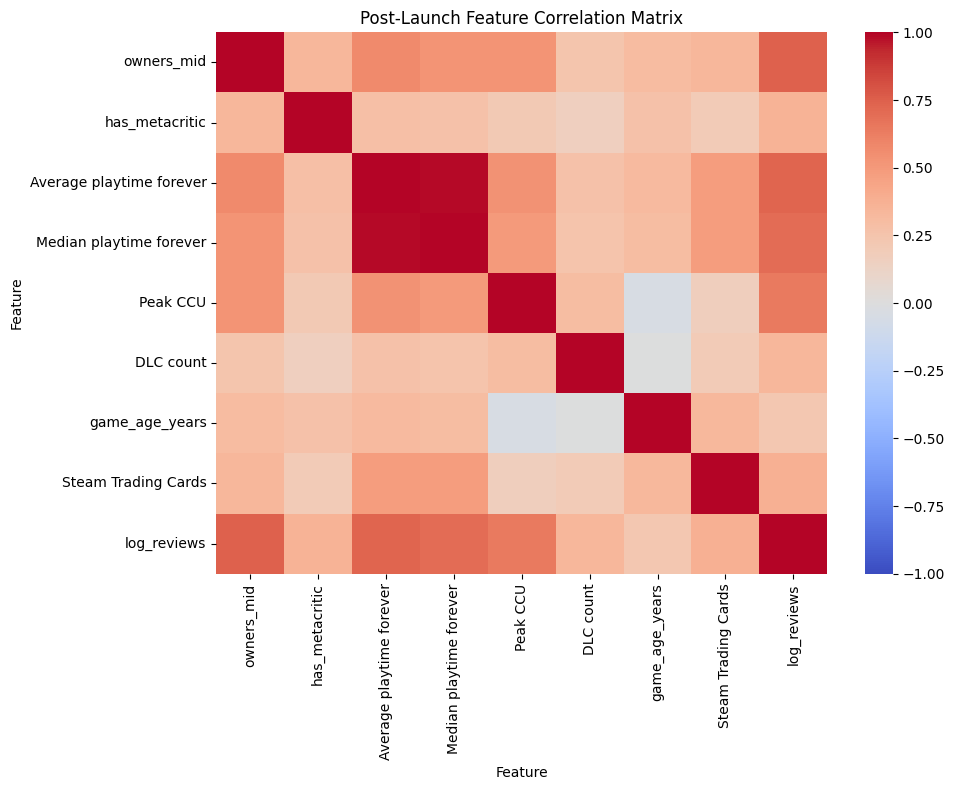

In [30]:
post_launch_corr = clean_data[post_launch+['log_reviews']].corr()


plt.figure(figsize=(10, 8))
sns.heatmap(post_launch_corr, vmin=-1, vmax=1, center=0, cmap='coolwarm')
plt.title('Post-Launch Feature Correlation Matrix')
plt.xlabel('Feature')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [31]:
all_features = pre_launch + post_launch
post_launch_corr = clean_data[all_features+['log_reviews']].corr()

top_pre_launch = [(name, val) 
                    for name in pre_launch_corr.abs()['log_reviews'].keys() 
                    for val in pre_launch_corr.abs()['log_reviews'] 
                    if (pre_launch_corr.abs()['log_reviews'][name] == val) and (name != 'log_reviews') ]
    
top_post_launch = [(name, val) 
                    for name in post_launch_corr.abs()['log_reviews'].keys() 
                    for val in post_launch_corr.abs()['log_reviews'] 
                    if (post_launch_corr.abs()['log_reviews'][name] == val) and (name != 'log_reviews') ]

In [32]:
top_pre_launch = [x[0] for x in sorted( top_pre_launch,reverse=True, key=lambda x: x[1])[:3]]
top_post_launch = [x[0] for x in sorted( top_post_launch,reverse=True, key=lambda x: x[1])[:3]]

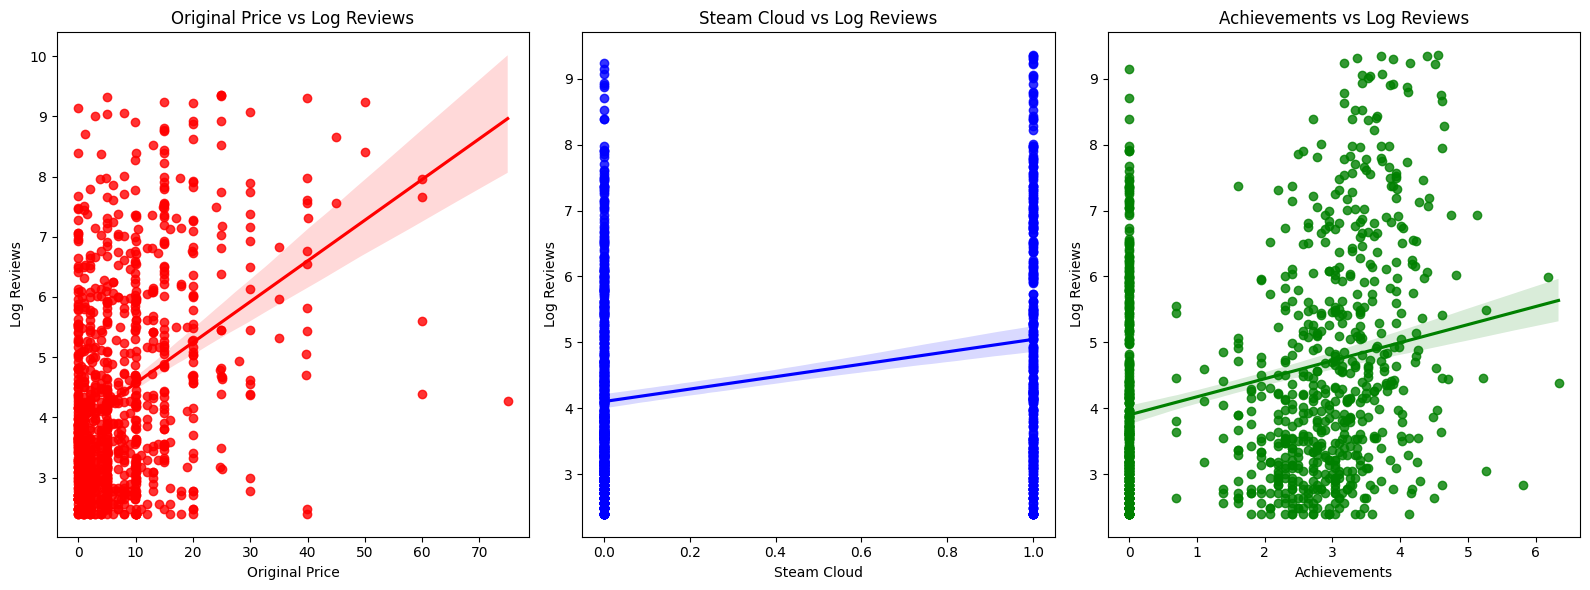

In [33]:
colors = ['red', 'blue', 'green']

sample = clean_data.sample(n=1000,random_state=42)

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 6))
for i, feature in enumerate(top_pre_launch):
    sns.regplot(ax=axes[i], x=sample[feature], y=sample['log_reviews'], color=colors[i])
    axes[i].set_title(f'{feature.replace("_", " ").title()} vs Log Reviews')
    axes[i].set_xlabel(feature.replace("_", " ").title())
    axes[i].set_ylabel('Log Reviews')
plt.tight_layout()
plt.show()

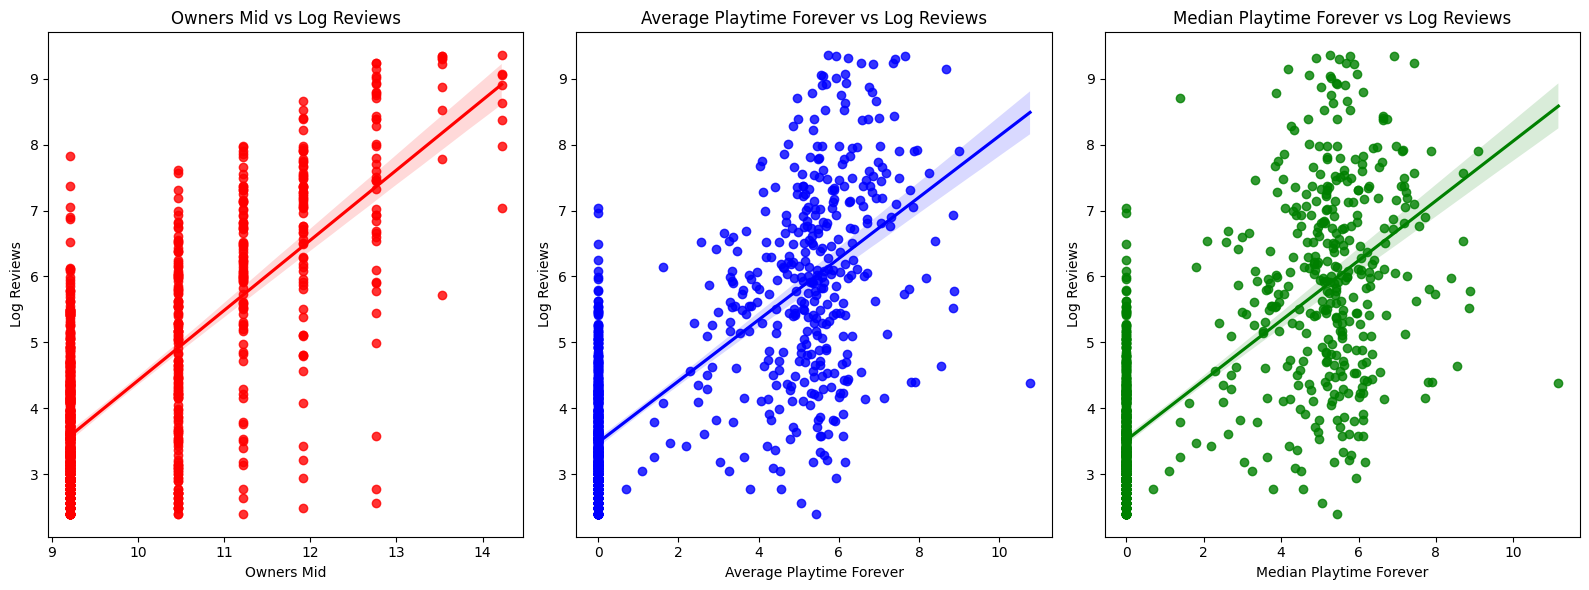

In [34]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 6))
for i, feature in enumerate(top_post_launch):
    sns.regplot(ax=axes[i], x=sample[feature], y=sample['log_reviews'], color=colors[i])
    axes[i].set_title(f'{feature.replace("_", " ").title()} vs Log Reviews')
    axes[i].set_xlabel(feature.replace("_", " ").title())
    axes[i].set_ylabel('Log Reviews')
plt.tight_layout()
plt.show()

In [35]:
upper_triangle = post_launch_corr.abs().where(np.triu(np.ones(post_launch_corr.shape), k=1).astype(bool))

threshold = 0.4
high_colinearity = [(col, upper_triangle.index[row], upper_triangle[col].values[row]) 
                    for col in upper_triangle.columns
                    for row in range(len(upper_triangle))
                    if (upper_triangle[col].values[row] > threshold)
                    and (col != 'log_reviews') 
                    and (upper_triangle.index[row] != 'log_reviews')]

high_colinearity

[('Free To Play', 'is_free', np.float64(0.716336848042988)),
 ('Family Sharing', 'is_free', np.float64(0.9012653191510516)),
 ('Family Sharing', 'Free To Play', np.float64(0.6845180190975088)),
 ('Steam Achievements', 'Achievements', np.float64(0.8108592132908121)),
 ('PvP', 'Multi-player', np.float64(0.7271313748740945)),
 ('Co-op', 'Multi-player', np.float64(0.6996948868519601)),
 ('Average playtime forever', 'owners_mid', np.float64(0.5720065953371696)),
 ('Median playtime forever', 'owners_mid', np.float64(0.5296708229370033)),
 ('Median playtime forever',
  'Average playtime forever',
  np.float64(0.991255726828879)),
 ('Peak CCU', 'owners_mid', np.float64(0.5248610420045754)),
 ('Peak CCU', 'Average playtime forever', np.float64(0.5335349333754341)),
 ('Peak CCU', 'Median playtime forever', np.float64(0.4927123307569924)),
 ('game_age_years', 'n_tags', np.float64(0.46843612945399754)),
 ('Steam Trading Cards',
  'Average playtime forever',
  np.float64(0.4831795510032371)),
 ('St

In [36]:
#dropping median playtime forever, and Free to Play
pre_launch.remove('Free To Play')
pre_launch.remove('is_free')
post_launch.remove('Median playtime forever')
all_features = pre_launch + post_launch

In [37]:
print("Pre-launch feature list:")
for feature in pre_launch:
    print(f' - {feature}')
print("Post Launch Features")
for feature in post_launch:
    print(f' - {feature}')

Pre-launch feature list:
 - original_price
 - Required age
 - n_languages
 - n_tags
 - n_screenshots
 - n_platforms
 - Achievements
 - Indie
 - Adventure
 - Action
 - Casual
 - Simulation
 - Strategy
 - RPG
 - Early Access
 - Sports
 - Single-player
 - Family Sharing
 - Steam Achievements
 - Steam Cloud
 - Full controller support
 - Multi-player
 - Partial Controller Support
 - PvP
 - Co-op
Post Launch Features
 - owners_mid
 - has_metacritic
 - Average playtime forever
 - Peak CCU
 - DLC count
 - game_age_years
 - Steam Trading Cards


# Part 3

In [38]:
#splitting data into 3 sets
seed = 5
test_data = clean_data.sample(frac=0.2,random_state=seed)
train_data = clean_data.drop(test_data.index)
validation_data = train_data.sample(frac=0.25,random_state=seed)
train_data = train_data.drop(validation_data.index)

y = 'log_reviews'

In [39]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import  root_mean_squared_error, r2_score, mean_absolute_error, median_absolute_error
from sklearn.model_selection import KFold, cross_validate
from sklearn.impute import SimpleImputer
from scipy import stats

In [40]:
dumb_model = DummyRegressor(strategy='mean').fit(train_data[pre_launch], train_data[y])

In [41]:
#from part 2 the best feature is owners_mid
simple_lr_model = LinearRegression().fit(train_data[['owners_mid']], train_data[y])

In [42]:
mlr_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',StandardScaler()),
    ('lr',LinearRegression())]).fit(train_data[pre_launch],train_data[y])

In [43]:
dumb_y_train_pred = dumb_model.predict(train_data[pre_launch])
dumb_y_validation_pred = dumb_model.predict(validation_data[pre_launch])

lr_y_train_pred = simple_lr_model.predict(train_data[['owners_mid']])
lr_y_validation_pred = simple_lr_model.predict(validation_data[['owners_mid']])

mlr_y_train_pred = mlr_model.predict(train_data[pre_launch])
mlr_y_validation_pred = mlr_model.predict(validation_data[pre_launch])

In [44]:
results = pd.DataFrame(
    [
        ["Dumb", 
         root_mean_squared_error(train_data[y],dumb_y_train_pred), root_mean_squared_error(validation_data[y],dumb_y_validation_pred),
         r2_score(train_data[y],dumb_y_train_pred), r2_score(validation_data[y],dumb_y_validation_pred),
         mean_absolute_error(train_data[y],dumb_y_train_pred), mean_absolute_error(validation_data[y],dumb_y_validation_pred)
        ],
        ["Simple LR",
         root_mean_squared_error(train_data[y],lr_y_train_pred), root_mean_squared_error(validation_data[y],lr_y_validation_pred),
         r2_score(train_data[y],lr_y_train_pred), r2_score(validation_data[y],lr_y_validation_pred),
         mean_absolute_error(train_data[y],lr_y_train_pred), mean_absolute_error(validation_data[y],lr_y_validation_pred),
        ],
        ["MLR",
         root_mean_squared_error(train_data[y],mlr_y_train_pred), root_mean_squared_error(validation_data[y],mlr_y_validation_pred),
         r2_score(train_data[y],mlr_y_train_pred), r2_score(validation_data[y],mlr_y_validation_pred),
         mean_absolute_error(train_data[y],mlr_y_train_pred), mean_absolute_error(validation_data[y],mlr_y_validation_pred),
        ]
        ],
        columns=['Model', 'Train RMSE', 'Valiation RMSE', 'Train R2', 'Validation R2', 'Train MAE', "Validation MAE"])

In [45]:
results

,Model,Train RMSE,Valiation RMSE,Train R2,Validation R2,Train MAE,Validation MAE
0,Dumb,1.660108,1.661832,0.000000,-0.000016,1.359007,1.363146
1,Simple LR,1.102271,1.106389,0.559137,0.556750,0.874215,0.877003
2,MLR,1.449139,1.462720,0.238014,0.225261,1.165772,1.176002


The simple linear model outperforms both other models, showing that the single best feature is worth more than all pre launch features together

In [46]:
coefficient_values = mlr_model.named_steps['lr'].coef_
coefficients = []
for i in range(len(pre_launch)):
    coefficients.append([pre_launch[i],coefficient_values[i]])
coefficients = sorted(coefficients,key=lambda x: x[1], reverse=True)

pd.DataFrame(coefficients, columns=['Feature', 'Coefficient'])

,Feature,Coefficient
0,Achievements,0.306560
1,original_price,0.292339
2,Multi-player,0.266607
3,Steam Cloud,0.217409
4,n_tags,0.194060
5,Required age,0.183111
6,n_platforms,0.153812
7,n_screenshots,0.130134
8,Simulation,0.099436
9,n_languages,0.091143


Achievements, price, platforms, and number of screenshots are the pre-launch decisions most correlated to more reviews

# Part 4

In [47]:
new_mlr_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',StandardScaler()),
    ('lr',LinearRegression())]).fit(train_data[all_features],train_data[y])

In [48]:
new_mlr_y_train_pred = new_mlr_model.predict(train_data[all_features])
new_mlr_y_validation_pred = new_mlr_model.predict(validation_data[all_features])


In [49]:
results = pd.DataFrame(
    [

        ["Pre-Launch",
         root_mean_squared_error(train_data[y],mlr_y_train_pred), root_mean_squared_error(validation_data[y],mlr_y_validation_pred),
         r2_score(train_data[y],mlr_y_train_pred), r2_score(validation_data[y],mlr_y_validation_pred),
         mean_absolute_error(train_data[y],mlr_y_train_pred), mean_absolute_error(validation_data[y],mlr_y_validation_pred),
        ],
        ["All Features",
        root_mean_squared_error(train_data[y],new_mlr_y_train_pred), root_mean_squared_error(validation_data[y],new_mlr_y_validation_pred),
        r2_score(train_data[y],new_mlr_y_train_pred), r2_score(validation_data[y],new_mlr_y_validation_pred),
        mean_absolute_error(train_data[y],new_mlr_y_train_pred), mean_absolute_error(validation_data[y],new_mlr_y_validation_pred),
        ]
        ],
        columns=['Model', 'Train RMSE', 'Valiation RMSE', 'Train R2', 'Validation R2', 'Train MAE', "Validation MAE"])
results

,Model,Train RMSE,Valiation RMSE,Train R2,Validation R2,Train MAE,Validation MAE
0,Pre-Launch,1.449139,1.462720,0.238014,0.225261,1.165772,1.176002
1,All Features,0.819646,0.823041,0.756230,0.754712,0.648073,0.648643


In [50]:
poly_lr_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('poly', PolynomialFeatures(degree=2)),
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
]).fit(train_data[all_features],train_data[y])


In [51]:
def show_model_results(models):
    results = []
    for x in models:
        name:str = x[0]
        model = x[1]
        train_pred = model.predict(train_data[all_features])
        validation_pred = model.predict(validation_data[all_features])
        row = [name,
                         root_mean_squared_error(train_data[y],train_pred), root_mean_squared_error(validation_data[y],validation_pred),
                         r2_score(train_data[y],train_pred), r2_score(validation_data[y],validation_pred),
                         mean_absolute_error(train_data[y],train_pred), mean_absolute_error(validation_data[y],validation_pred),
                        ]
        results.append(row)
    return pd.DataFrame(results, columns=['Model', 'Train RMSE', 'Validation RMSE', 'Train R2', 'Validation R2', 'Train MAE', "Validation MAE"])
    

In [52]:
alphas = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0, 1000.0]
ridge_models = []

for alpha in alphas:
    model = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('poly', PolynomialFeatures(degree=2)),
        ('scaler', StandardScaler()),
        ('model', Ridge(alpha=alpha))
        ]).fit(train_data[all_features],train_data[y])
    ridge_models.append((f"Ridge a={alpha}",model))

In [53]:
alphas = [0.0001, 0.001, 0.01, 0.1]
lasso_models = []

for alpha in alphas:
    model = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('poly', PolynomialFeatures(degree=2)),
        ('scaler', StandardScaler()),
        ('model', Lasso(alpha=alpha,max_iter=2000))
        ]).fit(train_data[all_features],train_data[y])
    lasso_models.append((f"Lasso a={alpha}",model))

C:\Users\tjran\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.250405e+03, tolerance: 9.080e+00
  model = cd_fast.enet_coordinate_descent(


In [54]:
results = show_model_results([("LR d=2",poly_lr_model)]+ridge_models+lasso_models)
results = results.sort_values(by='Validation R2', ascending=False)
results

,Model,Train RMSE,Validation RMSE,Train R2,Validation R2,Train MAE,Validation MAE
8,Lasso a=0.0001,0.745632,0.753495,0.798267,0.794414,0.586827,0.590058
0,LR d=2,0.745447,0.753734,0.798367,0.794283,0.586728,0.590300
1,Ridge a=0.001,0.745447,0.753734,0.798367,0.794283,0.586728,0.590300
2,Ridge a=0.01,0.745447,0.753735,0.798367,0.794283,0.586728,0.590300
3,Ridge a=0.1,0.745447,0.753736,0.798367,0.794282,0.586728,0.590300
4,Ridge a=1.0,0.745448,0.753750,0.798367,0.794275,0.586730,0.590302
5,Ridge a=10.0,0.745540,0.753925,0.798317,0.794179,0.586802,0.590366
6,Ridge a=100.0,0.747787,0.756045,0.797099,0.793020,0.588415,0.591822
9,Lasso a=0.001,0.750973,0.756051,0.795367,0.793017,0.591077,0.591907
7,Ridge a=1000.0,0.759595,0.766066,0.790641,0.787497,0.598507,0.600743


In [55]:
results['RMSE Gap'] = results['Validation RMSE'] - results['Train RMSE']
results['R2 Gap'] = results['Validation R2'] - results['Train R2']
results

,Model,Train RMSE,Validation RMSE,Train R2,Validation R2,Train MAE,Validation MAE,RMSE Gap,R2 Gap
8,Lasso a=0.0001,0.745632,0.753495,0.798267,0.794414,0.586827,0.590058,0.007863,-0.003853
0,LR d=2,0.745447,0.753734,0.798367,0.794283,0.586728,0.590300,0.008287,-0.004084
1,Ridge a=0.001,0.745447,0.753734,0.798367,0.794283,0.586728,0.590300,0.008287,-0.004084
2,Ridge a=0.01,0.745447,0.753735,0.798367,0.794283,0.586728,0.590300,0.008288,-0.004084
3,Ridge a=0.1,0.745447,0.753736,0.798367,0.794282,0.586728,0.590300,0.008289,-0.004085
4,Ridge a=1.0,0.745448,0.753750,0.798367,0.794275,0.586730,0.590302,0.008302,-0.004092
5,Ridge a=10.0,0.745540,0.753925,0.798317,0.794179,0.586802,0.590366,0.008385,-0.004138
6,Ridge a=100.0,0.747787,0.756045,0.797099,0.793020,0.588415,0.591822,0.008257,-0.004079
9,Lasso a=0.001,0.750973,0.756051,0.795367,0.793017,0.591077,0.591907,0.005078,-0.002350
7,Ridge a=1000.0,0.759595,0.766066,0.790641,0.787497,0.598507,0.600743,0.006471,-0.003144


Lasso a=0.0001 is both the highest validation R2 and lowest validation RMSE and MAE, so I will use that as my chosen model

In [56]:
model = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('poly', PolynomialFeatures(degree=2)),
        ('scaler', StandardScaler()),
        ('model', Lasso(alpha=0.0001, max_iter=2000))
        ]).fit(train_data[all_features],train_data[y])

C:\Users\tjran\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.250405e+03, tolerance: 9.080e+00
  model = cd_fast.enet_coordinate_descent(


In [57]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_results = cross_validate(
    model, validation_data[all_features], validation_data[y], 
    cv=kf, 
    scoring=['r2', 'neg_root_mean_squared_error'])

cv_rmse = -cv_results['test_neg_root_mean_squared_error']
cv_r2 = cv_results['test_r2']

print(f'RMSE Mean: {cv_rmse.mean():.6f} Std: ±{cv_rmse.std():.6f}')
print(f'R² Mean: {cv_r2.mean():.6f} Std: ±{cv_r2.std():.6f}')

C:\Users\tjran\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.289102e+02, tolerance: 2.431e+00
  model = cd_fast.enet_coordinate_descent(
C:\Users\tjran\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.977999e+02, tolerance: 2.433e+00
  model = cd_fast.enet_coordinate_descent(
C:\Users\tjran\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCach

RMSE Mean: 0.774101 Std: ±0.006013
R² Mean: 0.782932 Std: ±0.005201


C:\Users\tjran\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.763033e+02, tolerance: 2.420e+00
  model = cd_fast.enet_coordinate_descent(


In [58]:
train_and_validate = pd.concat([train_data,validation_data])

final_model = Pipeline([
        ('poly', PolynomialFeatures(degree=2, include_bias=False)),
        ('scaler', StandardScaler()),
        ('model', Lasso(alpha=0.0001, max_iter=6000))
        ]).fit(train_and_validate[all_features],train_and_validate[y])

In [59]:
final_pred = final_model.predict(test_data[all_features])

print(f"Test MSE: {root_mean_squared_error(test_data[y],final_pred)**2}")
print(f"Test RMSE: {root_mean_squared_error(test_data[y],final_pred)}")
print(f"Test MAE: {mean_absolute_error(test_data[y],final_pred)}")
print(f"Test R2: {r2_score(test_data[y],final_pred)}")

Test MSE: 0.5629588366925764
Test RMSE: 0.7503058287742248
Test MAE: 0.5916581748593953
Test R2: 0.7934836168068347


In [60]:
print(f'Median Absolute Error (in number of reviews): {np.expm1(median_absolute_error(test_data[y],final_pred))}')

Median Absolute Error (in number of reviews): 0.6382157662199721


In [61]:
results = []
for x in [('Final',final_model),('Dumb', dumb_model),('Simple LR', simple_lr_model), ('MLR', mlr_model)]:
    name:str = x[0]
    model = x[1]
    if name == "Final":
        test_pred = model.predict(test_data[all_features])
    elif name == "Simple LR":
        test_pred = model.predict(test_data[['owners_mid']])
    else:
        test_pred = model.predict(test_data[pre_launch])
    row = [name,
                        root_mean_squared_error(test_data[y],test_pred),
                        r2_score(test_data[y],test_pred),
                        mean_absolute_error(test_data[y],test_pred),
                        np.expm1(median_absolute_error(test_data[y],test_pred))
                    ]
    results.append(row)
table = pd.DataFrame(results, columns=['Model', 'Test RMSE', 'Test R2', 'Test MAE', 'Median AE Reviews'])

table

,Model,Test RMSE,Test R2,Test MAE,Median AE Reviews
0,Final,0.750306,0.793484,0.591658,0.638216
1,Dumb,1.651133,-0.000097,1.354892,2.501046
2,Simple LR,1.101345,0.555037,0.869092,1.102313
3,MLR,1.451413,0.227213,1.170373,1.780294


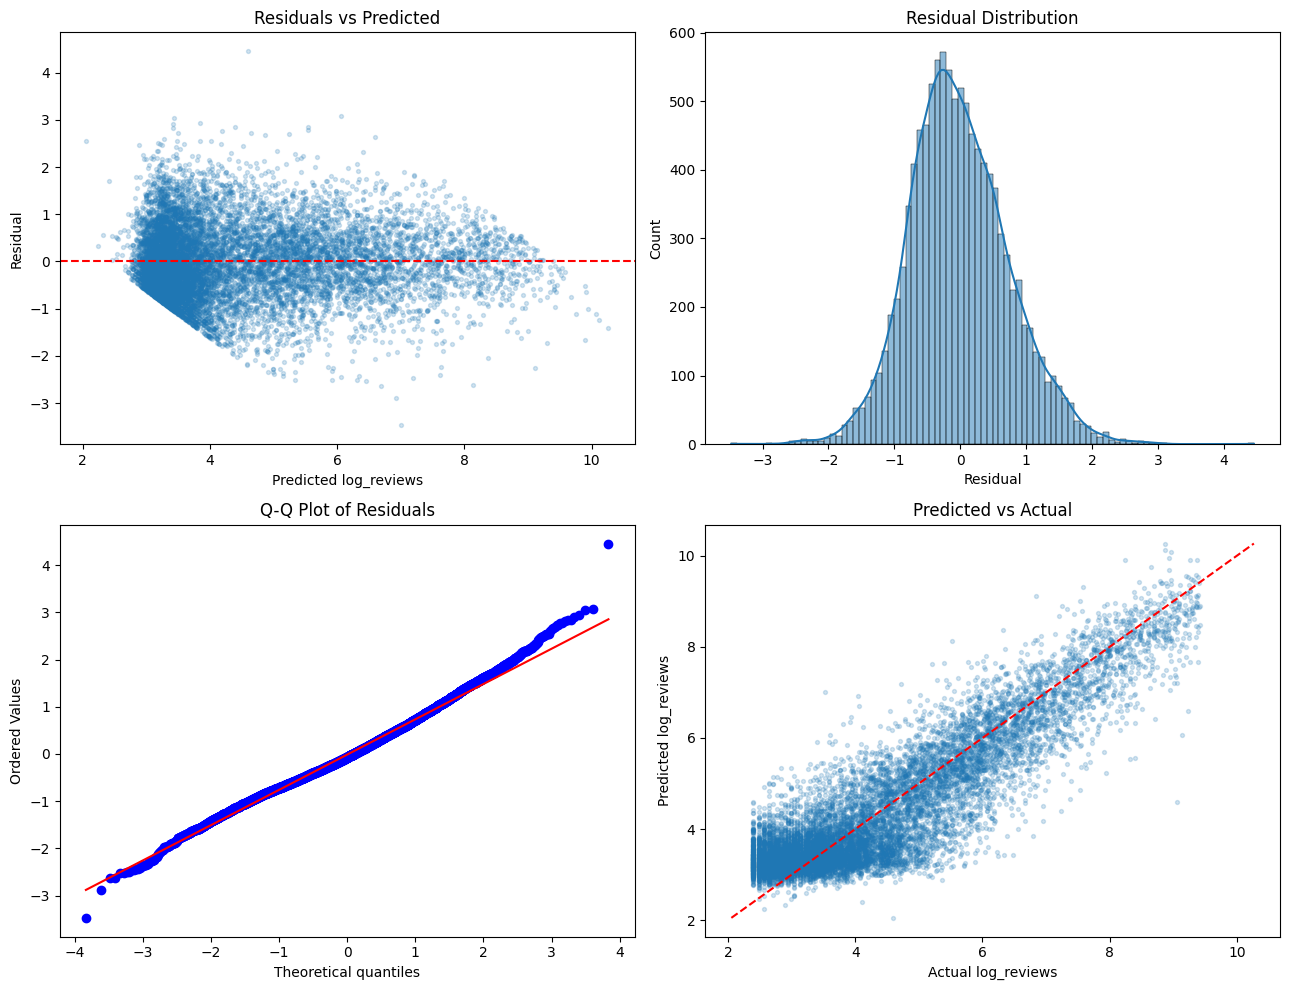

In [62]:
y_true = test_data[y].values
residuals = y_true - final_pred

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

axes[0,0].scatter(final_pred, residuals, alpha=0.2, s=8)
axes[0,0].axhline(0, color='red', linestyle='--')
axes[0,0].set(xlabel='Predicted log_reviews', ylabel='Residual', title='Residuals vs Predicted')

sns.histplot(residuals, kde=True, ax=axes[0,1])
axes[0,1].set(xlabel='Residual', title='Residual Distribution')

stats.probplot(residuals, dist='norm', plot=axes[1,0])
axes[1,0].set_title('Q-Q Plot of Residuals')

axes[1,1].scatter(y_true, final_pred, alpha=0.2, s=8)
lims = [min(y_true.min(), final_pred.min()), max(y_true.max(), final_pred.max())]
axes[1,1].plot(lims, lims, color='red', linestyle='--')
axes[1,1].set(xlabel='Actual log_reviews', ylabel='Predicted log_reviews', title='Predicted vs Actual')

plt.tight_layout()
plt.show()

The model seems to over-predict small titles, and under-predict hits

In [63]:
test_indices = test_data.index
errors = pd.DataFrame({
    'Name': df.loc[test_indices, 'Name'],
    'Log Reviews': test_data[y],
    'Prediction': final_pred,
    'Error': np.abs(residuals)})

In [64]:
errors.sort_values(by='Error', ascending=False).head(3)

,Name,Log Reviews,Prediction,Error
13446,Gear Up,9.059517,4.602043,4.457475
61320,DEATH TRAIN - Warning: Unsafe VR Experience,3.526361,7.000114,3.473754
3618,Cassette Beasts,9.137662,6.061779,3.075883


In [65]:
poly = final_model.named_steps['poly']
lasso = final_model.named_steps['model']

feature_names = poly.get_feature_names_out(all_features)
coefs = pd.Series(lasso.coef_, index=feature_names)

dropped = coefs[coefs == 0]

print(f'lasso dropped {dropped.count()} out of {coefs.count()} total features')

print(f'Featues dropped: {list(dropped.index)}')

lasso dropped 36 out of 560 total features
Featues dropped: ['n_platforms', 'Achievements', 'Sports', 'Multi-player', 'Partial Controller Support', 'original_price Average playtime forever', 'Required age owners_mid', 'n_languages Family Sharing', 'n_tags n_platforms', 'n_tags Steam Cloud', 'n_tags Multi-player', 'n_platforms^2', 'n_platforms Co-op', 'n_platforms owners_mid', 'Achievements Adventure', 'Achievements Strategy', 'Achievements Sports', 'Achievements Family Sharing', 'Achievements PvP', 'Indie Partial Controller Support', 'Action owners_mid', 'Casual Single-player', 'Casual Multi-player', 'RPG^2', 'Sports^2', 'Sports Multi-player', 'Single-player DLC count', 'Family Sharing Multi-player', 'Family Sharing Co-op', 'Family Sharing has_metacritic', 'Full controller support PvP', 'Full controller support owners_mid', 'Multi-player^2', 'Partial Controller Support^2', 'Co-op^2', 'Co-op Steam Trading Cards']


# Conclusion

The final model was Lasso using degree=2 and alpha=0.0001. 
The model reached a R2 score of 0.7934 on the test data.

The single most important feature was owners_mid, which is unsurprising given that the number of owners is essentially the upper limit for a games reviews.
Strong pre-launch features include achievements, price and cloud saves. While we can't say if any of those have causal relationships with a game's success, the correlation means its not a bad idea for indie studios to consider them when launching their game.

A major limitation of the model is that it's limited to the information made publicly available through steam, were factors like production budget, marketing budget, peak twitch viewership, success of the developer's other titles, and more included in the dataset, the model likely would have performed much better.
